[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tester170/skyscapes-convnext-upernet/blob/v1.0/SkyScapes_ConvNeXt_UPerNet.ipynb)

# **DINOv3 ConvNeXt-B + UPerNet для DLR SkyScapes-Dense: инференс и дообучение на своих данных (MMSegmentation 1.2.2)**

Автономный блокнот: всё нужное он разворачивает сам, заранее ничего загружать не надо. Все файлы сохраняются в папку рядом с блокнотом, в Colab это локальный диск сессии `/content`. Исходный код и релиз с весами: https://github.com/tester170/skyscapes-convnext-upernet.

Модель — лучшая из сравнения четырёх моделей на наборе SkyScapes-Dense: кодировщик DINOv3 ConvNeXt-B (Meta, предобучение LVD-1689M) и декодер UPerNet, 122 млн параметров, 20 классов, лучшая эпоха 48. На валидационной выборке SkyScapes она даёт mIoU 43,3 % на 20 классах (κ = 0,791), 67,8 % при укрупнении до 9 классов и 76,5 % в схеме ISPRS из 6 классов.

Откуда берутся файлы:
* **код конвейера** (конфигурация, датасет, аугментации, метрики, хуки, скрипты) — клонируется из репозитория GitHub на метке релиза `v1.0`;
* **обученная модель** (466 МБ) и **MMCV 2.1.0** — файлы релиза `v1.0`, каждый проверяется по контрольной сумме;
* **код DINOv3** — официальный репозиторий facebookresearch/dinov3 на той версии, с которой обучалась модель;
* **окружение** — Python 3.11, PyTorch 2.1.0 + CUDA 12.1, MMEngine 0.10.7, MMSegmentation 1.2.2 с точными версиями эксперимента, ставится отдельно от окружения Colab;
* **набор DLR SkyScapes** — только для проверки модели в разделе 3, с официального сервера DLR с проверкой контрольной суммы.

Блокнот выполняет инференс по своим снимкам любого размера (раздел 2), оценку модели на валидационной выборке SkyScapes (раздел 3), дообучение на своих размеченных данных из папки `my_data` (разделы 4 и 5) и применение дообученной модели (раздел 6).

Для запуска выберите *Среда выполнения → Сменить среду выполнения → GPU* (T4 достаточно), затем *Среда выполнения → Выполнить все*. До готовности к инференсу проходит около 5 минут. Дообучение по умолчанию выключено (`TRAIN` в разделе 5), веса и результаты скачиваются кнопками раздела 7.

## **Параметры и загрузка пакета**

Все пути отсчитываются от папки блокнота (`ROOT`). В Colab это локальный диск сессии `/content`: он очищается при завершении сессии, поэтому нужные результаты скачайте кнопками раздела 7.

In [1]:
import os, sys, json
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
REPO      = 'tester170/skyscapes-convnext-upernet'            # репозиторий GitHub с кодом и релизом
TAG       = 'v1.0'                                 # версия (метка релиза)
ROOT      = os.environ.get('SKY_ROOT', os.getcwd())     # папка блокнота; в Colab — /content
BUNDLE    = f'{ROOT}/skyscapes_convnext'                # код и модель (из репозитория)
MY_IMAGES = f'{ROOT}/my_images'                         # свои снимки для инференса
MY_DATA   = f'{ROOT}/my_data'                           # свои размеченные данные для дообучения
DATA      = f'{ROOT}/data/SS_Dense'                     # набор SkyScapes (скачивается в разделе 3)
WORK      = f'{ROOT}/skyscapes_convnext_runs'           # результаты
CACHE_SKY = f'{ROOT}/cache_skyscapes'                   # кэш декодированных снимков SkyScapes
CACHE_OWN = f'{ROOT}/cache_my_data'                     # кэш своих данных
ENV       = f'{ROOT}/py311'                             # окружение Python 3.11
PY = f'{ENV}/bin/python'


def run(*args):
    # команда с выводом в реальном времени; при ошибке ячейка останавливается
    import subprocess
    env = {**os.environ, 'MPLBACKEND': 'Agg', 'PYTHONUNBUFFERED': '1'}
    p = subprocess.Popen([str(a) for a in args], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1, env=env)
    for line in p.stdout:
        print(line, end='', flush=True)
    if p.wait() != 0:
        raise RuntimeError(f'команда завершилась с ошибкой (код {p.returncode}): ' + ' '.join(map(str, args)))


def download_button(label, make_file):
    # кнопка: по нажатию файл готовится (make_file() возвращает путь) и скачивается браузером
    import ipywidgets as widgets
    from IPython.display import display
    out = widgets.Output()
    button = widgets.Button(description=label, icon='download', button_style='primary', layout=widgets.Layout(width='auto'))

    def click(_):
        with out:
            path = make_file()
            print(f'{Path(path).name}: {Path(path).stat().st_size / 2 ** 20:.1f} МБ')
            if IN_COLAB:
                from google.colab import files
                files.download(path)

    button.on_click(click)
    display(widgets.VBox([button, out]))


def zip_folder(folder, name):
    import shutil
    return shutil.make_archive(f'{ROOT}/{name}', 'zip', folder)


for d in (WORK, MY_IMAGES):
    Path(d).mkdir(parents=True, exist_ok=True)
print('папка блокнота:', ROOT)
print('свои снимки   :', MY_IMAGES)
print('свои данные   :', MY_DATA)
print('результаты    :', WORK)

папка блокнота: /content
свои снимки   : /content/my_images
свои данные   : /content/my_data
результаты    : /content/skyscapes_convnext_runs


Следующая ячейка клонирует код из репозитория на метке релиза и скачивает из релиза обученную модель (466 МБ) с проверкой контрольной суммы.

In [2]:
if not Path(BUNDLE, 'scripts', 'infer.py').exists():
    run('git', 'clone', '--quiet', '--depth', '1', '--branch', TAG, f'https://github.com/{REPO}.git', BUNDLE)
run('python3', f'{BUNDLE}/scripts/fetch.py', 'model')
CHECKPOINT = f'{BUNDLE}/checkpoints/convnext_b_upernet_skyscapes_ep48.pth'

Note: switching to 'a4a2b09dca63c2fd161c032e2bb0ed3e5f35b765'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

convnext_b_upernet_skyscapes_ep48.pth (466 MB) from tester170/skyscapes-convnext-upernet release v1.0
  convnext_b_upernet_skyscapes_ep48.pth: 4/466 MB (29.4 MB/s)
  convnext_b_upernet_skyscapes_ep48.pth: 48/466 MB (9.7 MB/s)
  convnext_b_upernet_skyscapes_ep48.pth: 96/466 MB (10.3 MB/s)
  convnext_b_upernet_skyscapes_ep48.pth: 140/466 MB (10.5 MB/s)
  convnext_b_upernet_skyscapes_ep48.pth: 188/466 MB (8.4 MB/s)
  co

## **1. Рабочее окружение**

Создаётся отдельное окружение Python 3.11 со строго зафиксированными версиями всех пакетов (`env/requirements.lock`, установка без подбора зависимостей). Первый запуск занимает 3–5 минут, повторный запуск в той же сессии ничего не переустанавливает.

Кодировщик модели строится официальным кодом DINOv3: он скачивается из репозитория facebookresearch/dinov3 на той версии, с которой обучалась модель. MMCV 2.1.0 (официальная сборка OpenMMLab для torch 2.1 и CUDA 12.1) берётся из релиза проекта, при его недоступности — с сервера OpenMMLab.

В конце проверяются версии пакетов, GPU, CUDA-операции MMCV и сборка кодировщика DINOv3.

In [3]:
run('bash', f'{BUNDLE}/env/setup_env.sh', ENV)

== official DINOv3 code (github.com/facebookresearch/dinov3, commit 6876159)
== installing uv (Python and package installer)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 100.9 MB/s eta 0:00:00
== creating Python 3.11 environment in /content/py311
Using CPython 3.11.17
Creating virtual environment with seed packages at: py311
 + packaging==26.3
 + pip==26.2.2
 + setuptools==84.2.1
 + wheel==0.48.0
Activate with: source py311/bin/activate
== installing pinned packages (PyTorch 2.1.0 cu121, MMEngine, MMSegmentation, ...): ~2-3 min
Using Python 3.11.17 environment at: py311
Resolved 62 packages in 1.06s
Prepared 60 packages in 1m 01s
Uninstalled 1 package in 72ms
Installed 60 packages in 796ms
 + addict==2.4.0
 + affine==3.0.1
 + attrs==26.1.0
 + certifi==2026.7.22
 + charset-normalizer==3.5.2
 + click==8.5.0
 + click-plugins==1.1.1.2
 + cligj==0.7.2
 + cloudpickle==3.1.2
 + contourpy==1.3.3
 + cycler==0.12.1
 + filelock==4.2.0
 + fonttools==4.67.0
 + fsspec==2026.9.0
 + ftfy==

## **2. Инференс по своим снимкам**

Снимки положите в папку `my_images` рядом с блокнотом (в Colab — `/content/my_images`, через панель «Файлы» слева) или задайте `UPLOAD = True`: тогда после запуска ячейки появится кнопка выбора файлов на компьютере. Подходят JPG/PNG/BMP/WEBP и растры GDAL — GeoTIFF, TIFF, JP2, IMG, VRT, любого размера: крупные растры читаются и обрабатываются по частям.

Модель обучена на 8-битных RGB-аэрофотоснимках с разрешением около 13 см (Мюнхен, камера DLR 3K). Снимки с другим разрешением лучше заранее привести к 13 см/пиксель. 16-битные данные пересчитываются в 8 бит, номера каналов RGB растра задаются в `BANDS`.

Для каждого снимка сохраняются:
* `<имя>_classes` — коды классов 1…20 (таблица кодов — в разделе 4);
* `<имя>_color` — цветная маска в палитре набора SkyScapes и `<имя>_preview.jpg` — снимок рядом с маской;
* `<имя>_L<n>_classes` и `_color` — маски укрупнённых схем из `SCHEMES` (легенда кодов — `schemes_legend.json`);
* `<имя>_conf` — карта уверенности (максимальная вероятность класса × 255).

Для георастров маски записываются в GeoTIFF с той же проекцией, привязкой и встроенной палитрой (в QGIS цвета классов видны сразу), для обычных снимков — в PNG. Под снимками появится кнопка скачивания всех масок одним архивом.

`FP16 = True` ускоряет обработку примерно вдвое: маски совпадают с вычислениями в полной точности (fp32) на 99,97 % пикселей.

In [13]:
UPLOAD   = True            # True — выбрать снимки на компьютере кнопкой
OUT_OWN  = f'{WORK}/my_images'
SCHEMES  = '9 6 5'          # укрупнённые схемы (число классов), '' — не нужны
BANDS    = ''               # номера каналов R G B растра, например '1 2 3'; '' — первые три
FP16     = True

import shutil
if UPLOAD and IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    if uploaded:
        shutil.rmtree(MY_IMAGES); Path(MY_IMAGES).mkdir()
        for name, content in uploaded.items():
            Path(MY_IMAGES, name).write_bytes(content)
own = sorted(p.name for p in Path(MY_IMAGES).iterdir() if p.is_file())
print('снимки:', own if own else f'нет — положите снимки в {MY_IMAGES} или задайте UPLOAD = True и запустите ячейку снова')
if own:
    args = ['--input', MY_IMAGES, '--out', OUT_OWN, '--checkpoint', CHECKPOINT, '--conf']
    args += ['--schemes', *SCHEMES.split()] if SCHEMES else []
    args += ['--bands', *BANDS.split()] if BANDS else []
    args += ['--fp16'] if FP16 else []
    run(PY, f'{BUNDLE}/scripts/infer.py', *args)

Saving 2012-04-26-Muenchen-Tunnel_4K0G0130.jpg to 2012-04-26-Muenchen-Tunnel_4K0G0130.jpg
снимки: ['2012-04-26-Muenchen-Tunnel_4K0G0130.jpg']
GPU Tesla T4: free 14.5 of 14.6 GB
/content/py311/lib/python3.11/site-packages/mmseg/models/builder.py:36: UserWarning: ``build_loss`` would be deprecated soon, please use ``mmseg.registry.MODELS.build()`` 
  warnings.warn('``build_loss`` would be deprecated soon, please use '
/content/py311/lib/python3.11/site-packages/mmseg/models/losses/cross_entropy_loss.py:250: UserWarning: Default ``avg_non_ignore`` is False, if you would like to ignore the certain label and average loss over non-ignore labels, which is the same with PyTorch official cross_entropy, set ``avg_non_ignore=True``.
  warnings.warn(
2012-04-26-Muenchen-Tunnel_4K0G0130.jpg: 5616x3744 -> masks in 12.4 s


2012-04-26-Muenchen-Tunnel_4K0G0130_preview.jpg


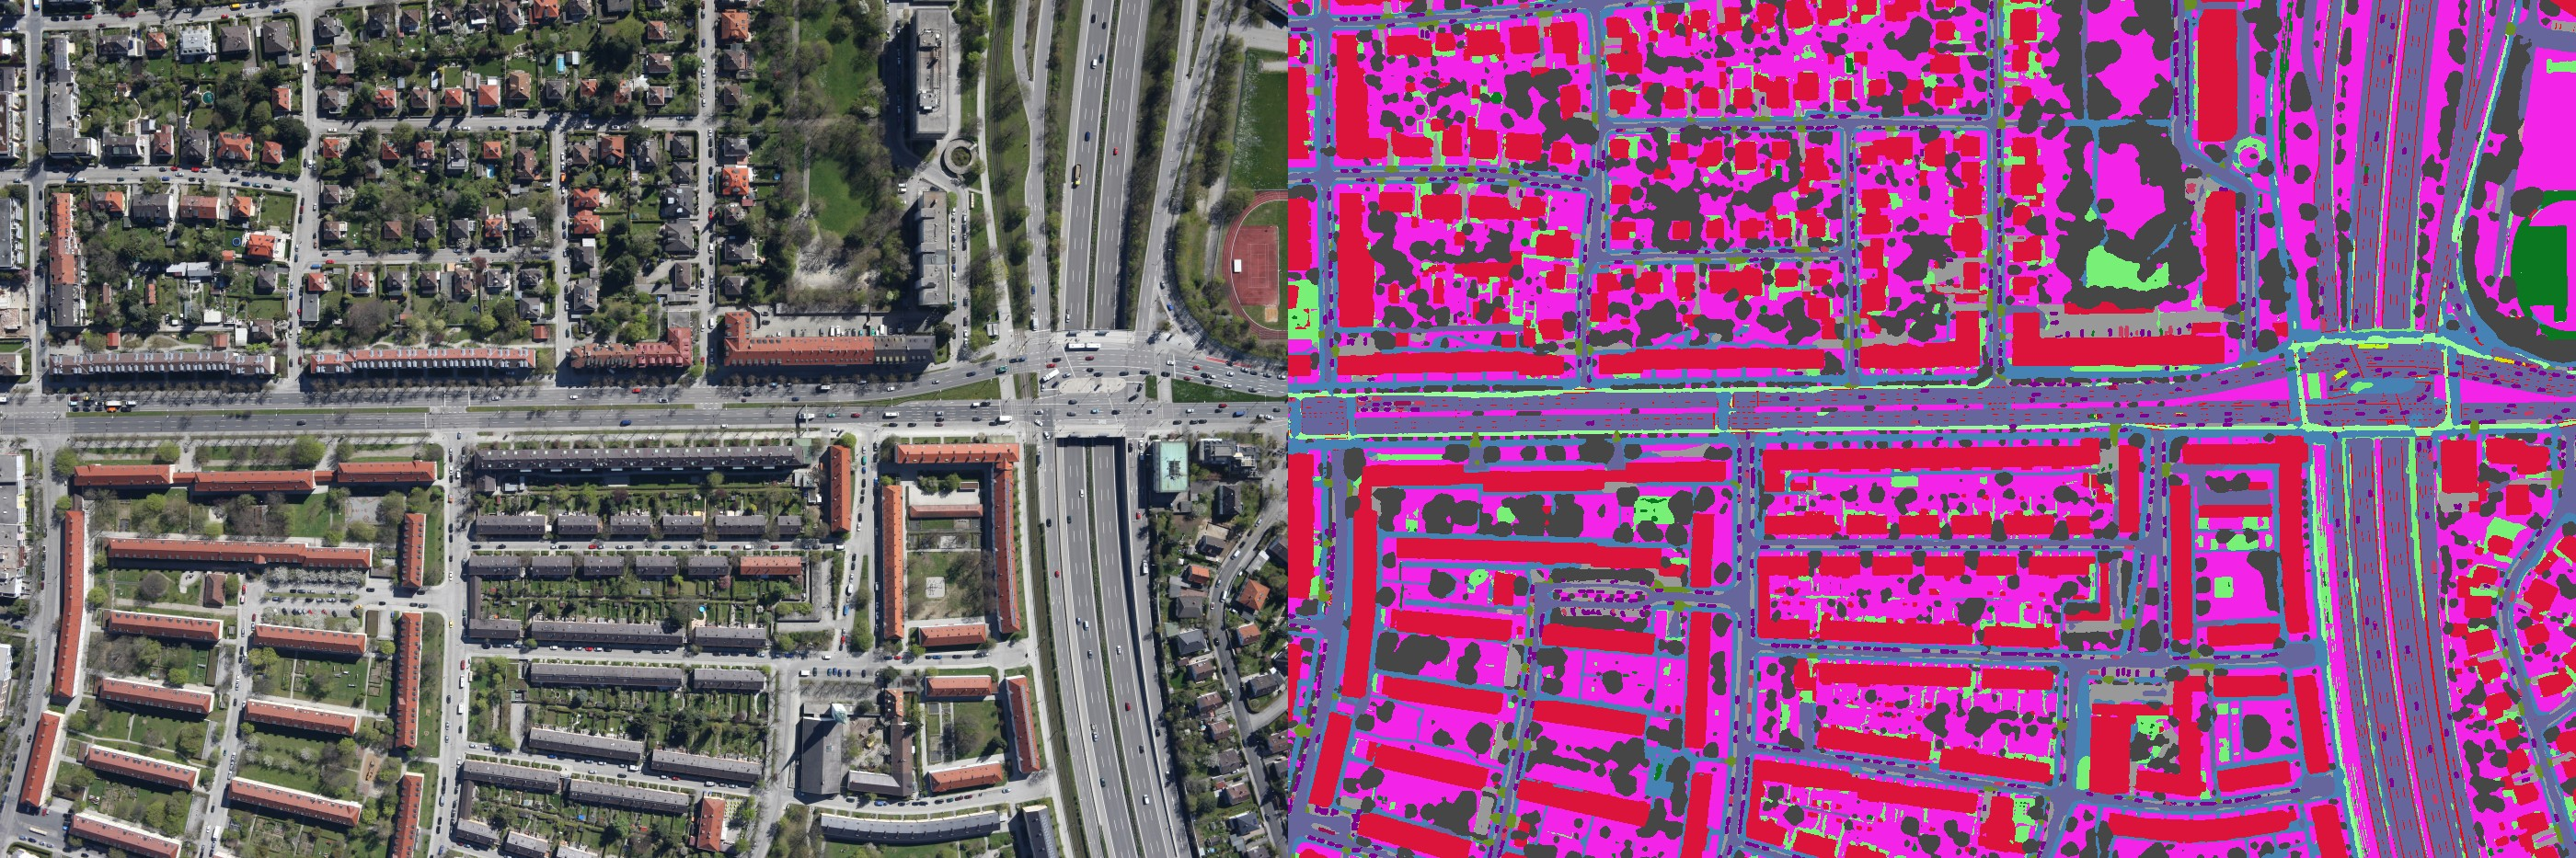

In [14]:
from IPython.display import Image, display
for p in sorted(Path(OUT_OWN).glob('*_preview.jpg'))[:5]:
    print(p.name); display(Image(str(p), width=1100))
if any(Path(OUT_OWN).glob('*_classes*')):
    download_button('Скачать маски своих снимков (.zip)', lambda: zip_folder(OUT_OWN, 'my_images_masks'))

## **3. Оценка модели на валидационной выборке SkyScapes**

Раздел проверяет модель на наборе, на котором она обучалась. Скачивается часть `SS_Dense` набора DLR SkyScapes (около 290 МБ, официальный сервер DLR, страница набора: https://www.dlr.de/en/eoc/about-us/remote-sensing-technology-institute/photogrammetry-and-image-analysis/public-datasets/dlr-skyscapes), снимки обучающей и валидационной выборок один раз декодируются в кэш.

Затем считаются все метрики — IoU, Dice/F1, Precision, Recall, Kappa, MCC, OA по классам и средние — для 20 классов и для каждого шага укрупнения 20 → 5 классов. Матрицы ошибок (200 dpi, κ класса на диагонали) сохраняются в папку `figures`. Ожидаемый результат: mIoU 43,27 % на 20 классах, κ = 0,791.

Раздел можно пропустить (`EVAL_SKYSCAPES = False`). Подготовленный здесь набор нужен и после дообучения: в разделе 5 новая модель проверяется на SkyScapes, чтобы видеть, сохранилось ли качество на исходных сценах.

При использовании набора авторы просят ссылаться на статью: S. Azimi et al., *SkyScapes — Fine-Grained Semantic Understanding of Aerial Scenes*, ICCV 2019.

In [6]:
EVAL_SKYSCAPES = os.environ.get('SKY_EVAL_SKYSCAPES', '1') == '1'
OUT_EVAL = f'{WORK}/evaluation_skyscapes'
if EVAL_SKYSCAPES:
    if not Path(DATA, 'val', 'images').exists():
        run('python3', f'{BUNDLE}/scripts/fetch.py', 'dataset', '--out', str(Path(DATA).parent))
    run(PY, f'{BUNDLE}/scripts/prepare_data.py', '--data', DATA, '--cache', CACHE_SKY)
    run(PY, f'{BUNDLE}/scripts/evaluate.py', '--cache', CACHE_SKY, '--checkpoint', CHECKPOINT, '--out', OUT_EVAL)
else:
    print('оценка на SkyScapes пропущена (EVAL_SKYSCAPES = False)')

official DLR archive https://pba-freesoftware.eoc.dlr.de/SkyScapes.zip (275 MB)
  SkyScapes.zip: 4/275 MB (3.0 MB/s)
  SkyScapes.zip: 32/275 MB (10.5 MB/s)
  SkyScapes.zip: 60/275 MB (13.1 MB/s)
  SkyScapes.zip: 88/275 MB (14.4 MB/s)
  SkyScapes.zip: 116/275 MB (15.2 MB/s)
  SkyScapes.zip: 144/275 MB (15.7 MB/s)
  SkyScapes.zip: 172/275 MB (15.9 MB/s)
  SkyScapes.zip: 200/275 MB (16.2 MB/s)
  SkyScapes.zip: 228/275 MB (16.4 MB/s)
  SkyScapes.zip: 256/275 MB (16.6 MB/s)
  SkyScapes.zip: 275/275 MB (16.7 MB/s)
dataset ready: /content/data/SS_Dense (images {'train': 8, 'val': 2, 'test': 6})
train/2012-04-26-Muenchen-Tunnel_4K0G0010: cached in 0.6 s
train/2012-04-26-Muenchen-Tunnel_4K0G0020: cached in 0.6 s
train/2012-04-26-Muenchen-Tunnel_4K0G0030: cached in 0.6 s
train/2012-04-26-Muenchen-Tunnel_4K0G0051: cached in 0.6 s
train/2012-04-26-Muenchen-Tunnel_4K0G0070: cached in 3.9 s
train/2012-04-26-Muenchen-Tunnel_4K0G0080: cached in 0.5 s
train/2012-04-26-Muenchen-Tunnel_4K0G0090: cached i

20 классов: mIoU 43.27 %, mDice 55.24 %, OA 82.61 %, kappa 0.7911
mIoU по числу классов: {20: 43.3, 19: 44.2, 18: 45.9, 17: 48.4, 16: 51.5, 15: 55.0, 14: 55.9, 13: 59.1, 12: 61.0, 11: 63.3, 10: 64.6, 9: 67.8, 8: 69.2, 7: 73.7, 6: 76.5, 5: 80.7}


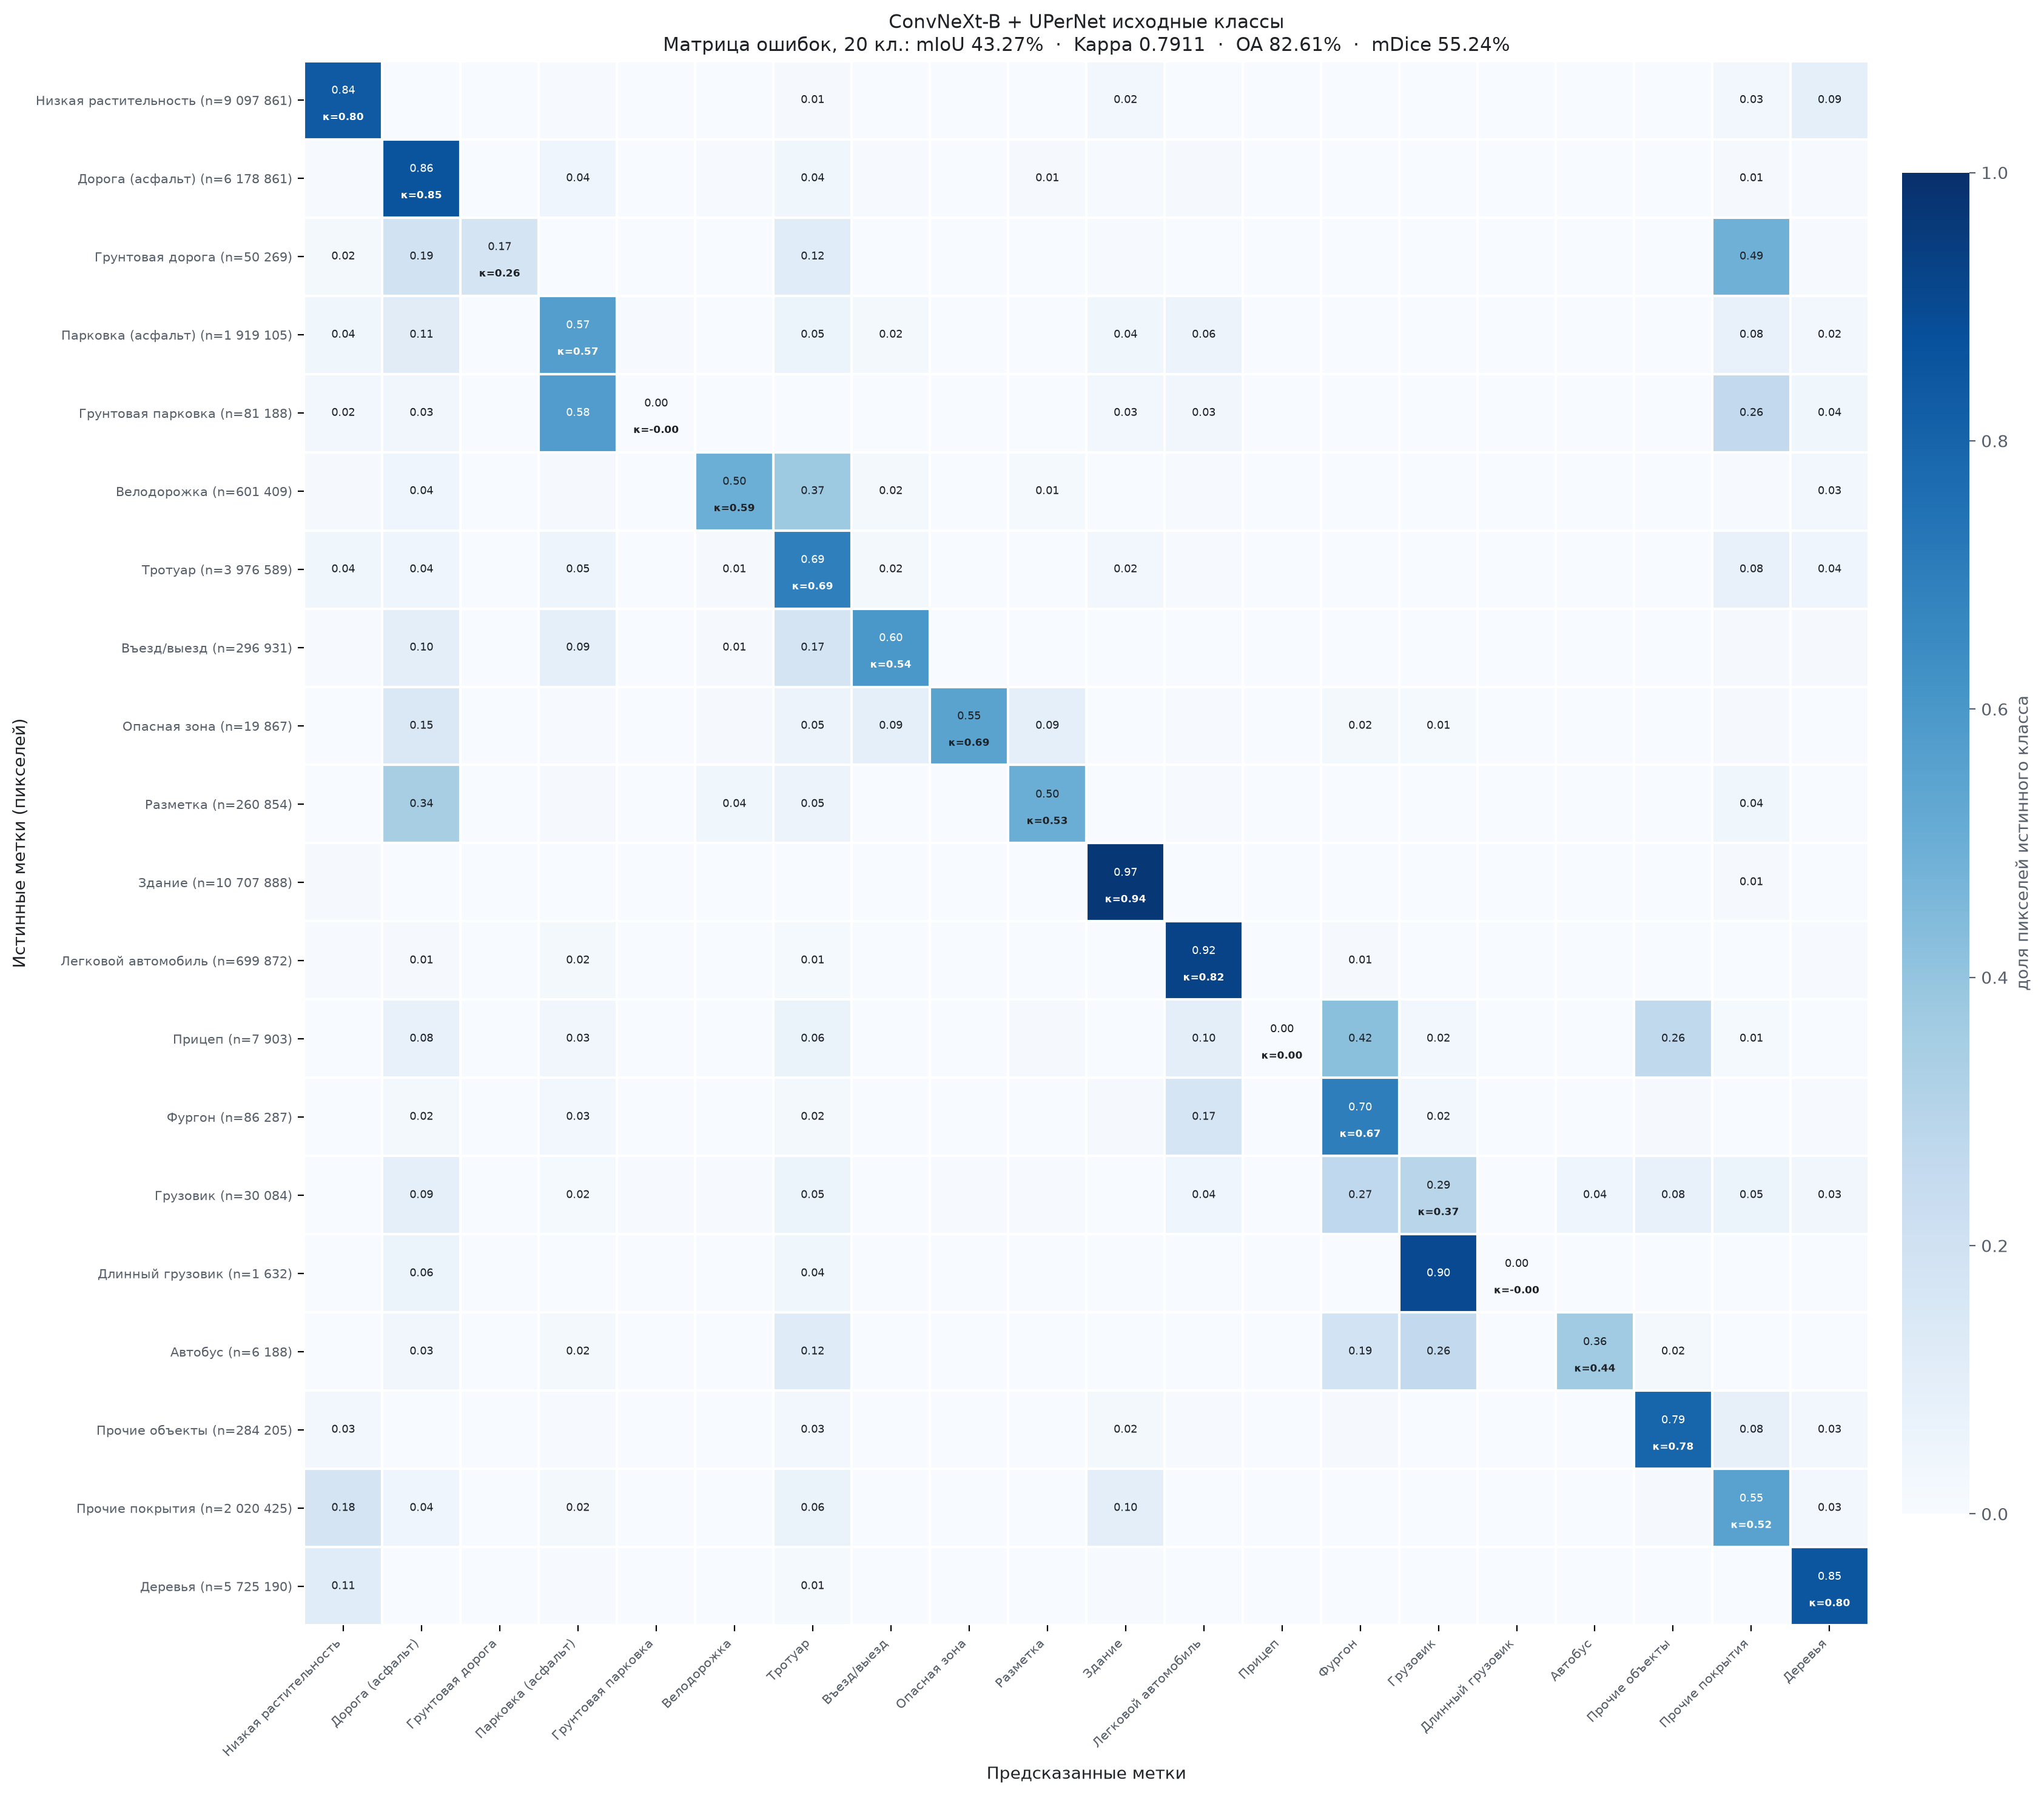

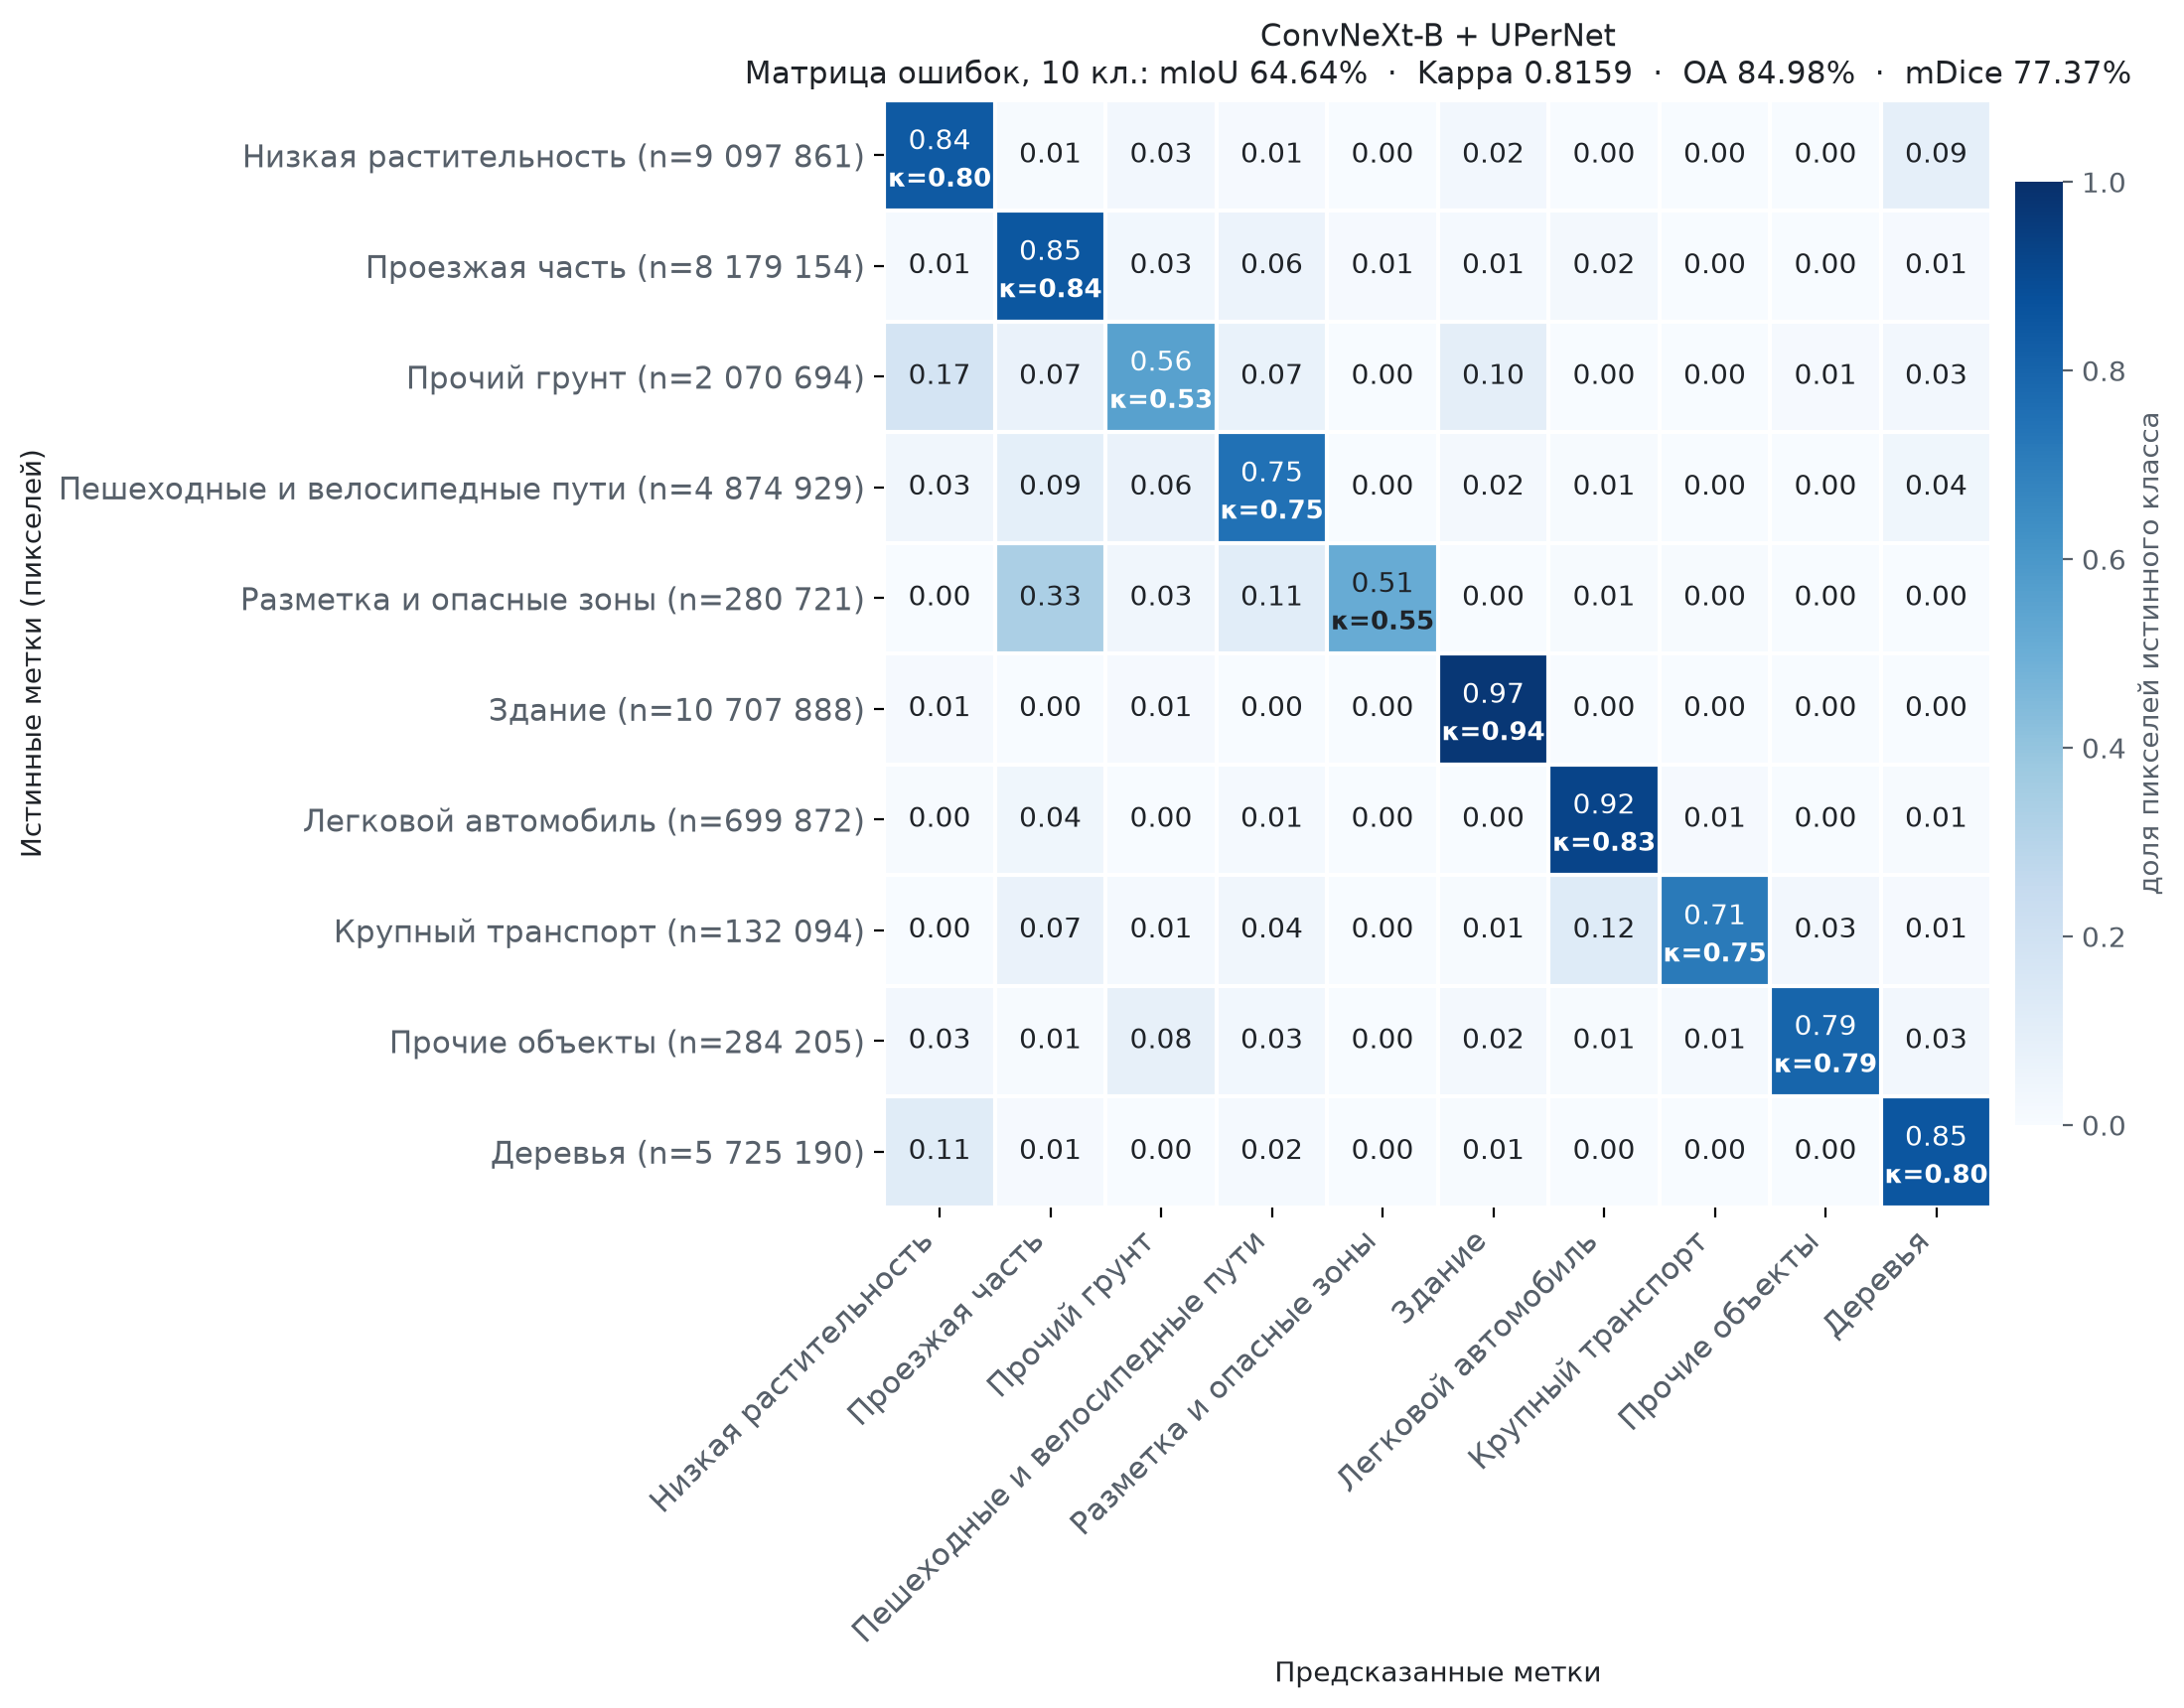

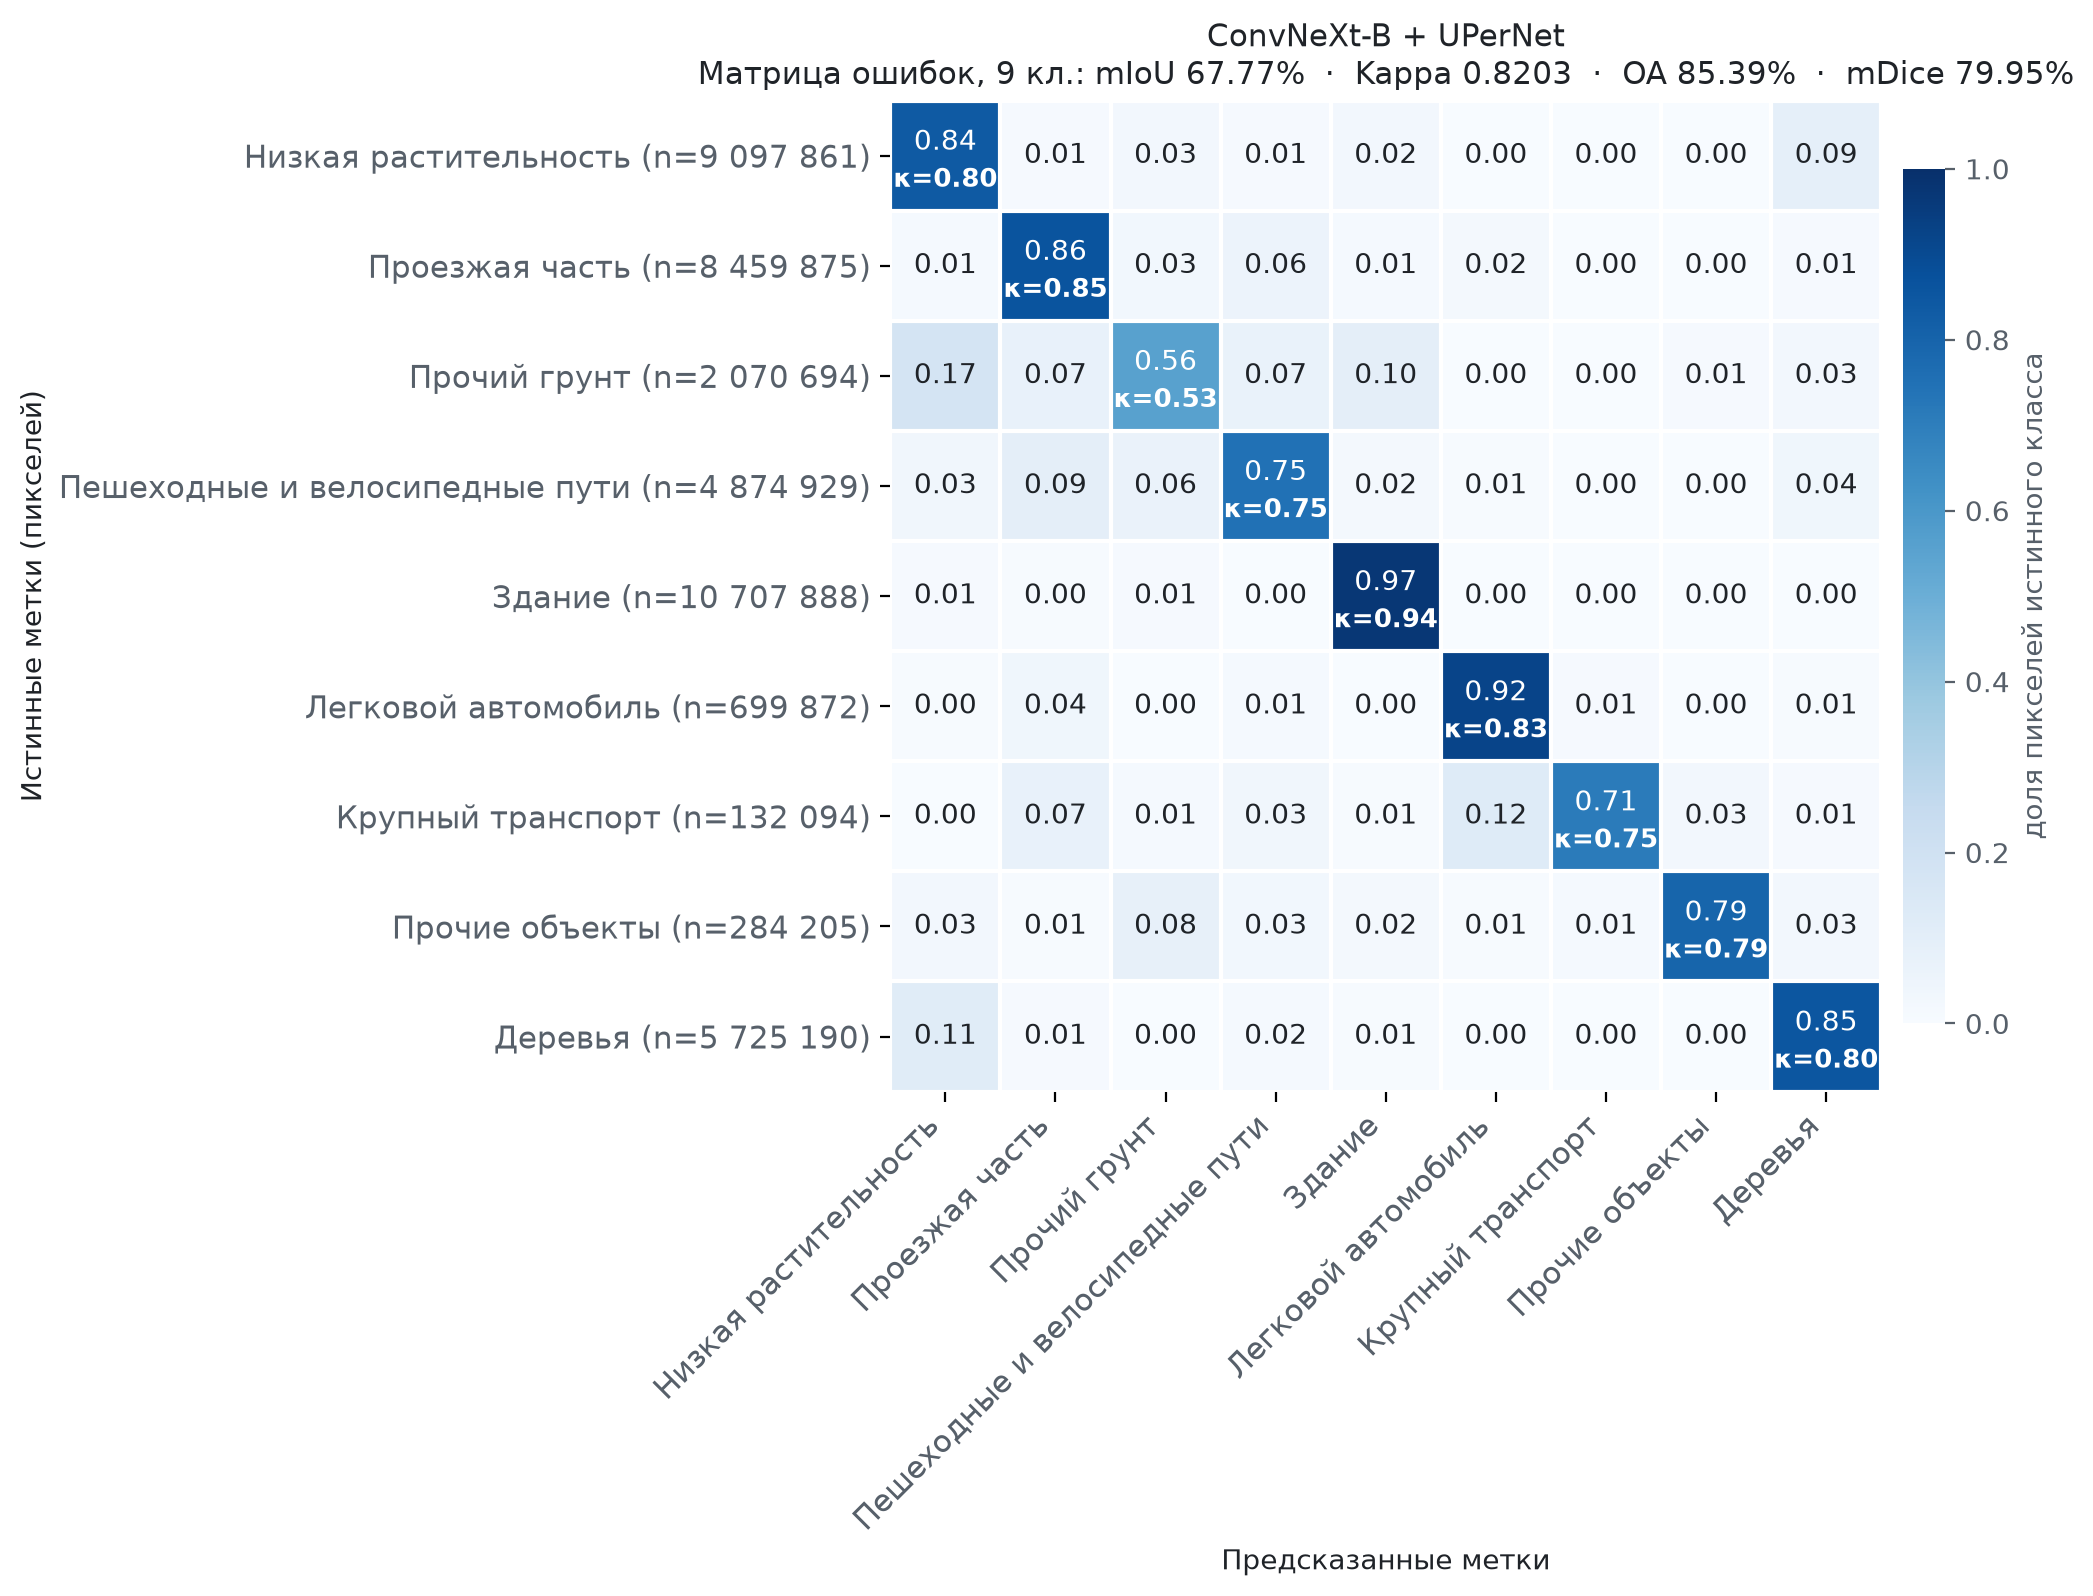

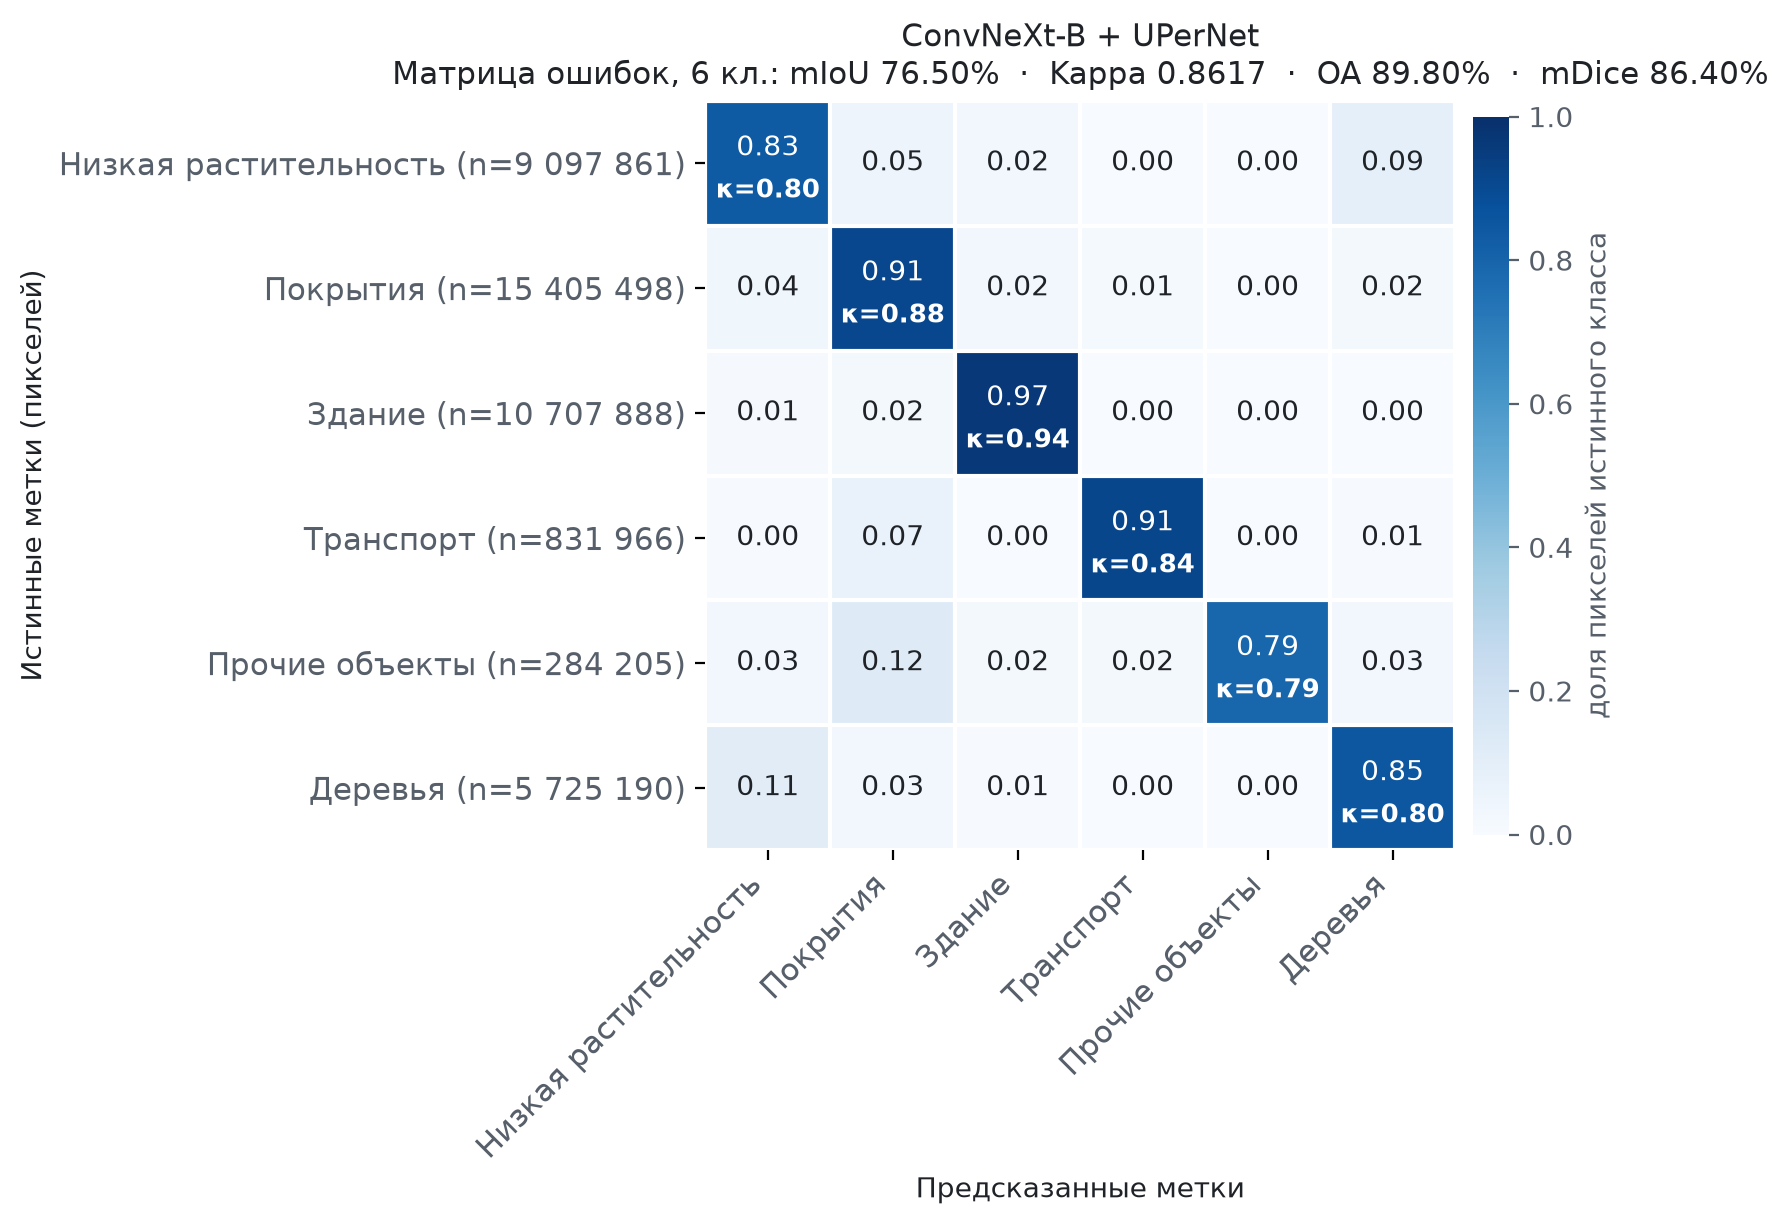

In [7]:
from IPython.display import Image, display


def show_eval(folder, levels=('L0_20', 'S10', 'S9', 'S6')):
    res = json.loads(Path(folder, 'eval.json').read_text())
    f = res['flat']
    print(f"20 классов: mIoU {f['mIoU']:.2f} %, mDice {f['mDice']:.2f} %, OA {f['aAcc']:.2f} %, kappa {f['kappa'] / 100:.4f}")
    print('mIoU по числу классов:', {int(k[6:]): round(v, 1) for k, v in f.items() if k.startswith('mIoU_S') and k[6:].isdigit()})
    for n in levels:
        p = Path(folder, 'figures', f'cm_{n}.png')
        if p.exists():
            display(Image(str(p), width=950))


if Path(OUT_EVAL, 'eval.json').exists():
    show_eval(OUT_EVAL)

## **4. Свои данные для дообучения**

Размеченные данные положите в папку `my_data` рядом с блокнотом (в Colab — `/content/my_data`). Удобнее всего упаковать папку в архив `my_data.zip` и загрузить его через панель «Файлы» слева: следующая ячейка распакует архив сама.

Структура папки (маска называется так же, как её снимок, отличается только расширение):
```
my_data/
├── train/                 обучающая часть
│   ├── images/            снимки
│   │   ├── участок_01.tif
│   │   └── участок_02.tif
│   └── masks/             маски с теми же именами
│       ├── участок_01.png
│       └── участок_02.png
└── val/                   проверочная часть (необязательно)
    ├── images/
    │   └── участок_03.tif
    └── masks/
        └── участок_03.png
```

Если папки `val` нет, для проверки откладывается каждый пятый снимок обучающей части (по алфавиту), поэтому снимков должно быть не меньше двух. Допускается и упрощённая структура без `train` и `val`: `my_data/images` и `my_data/masks`.

**Снимки:** GeoTIFF/TIFF, JP2, IMG, VRT, JPG, PNG, BMP или WEBP; 8-битные RGB (у многоканальных растров номера каналов R, G, B задаются в `BANDS`), разрешение около 13 см/пиксель, любой размер. Снимки меньше 1024 × 1024 пикселей тоже подходят: при обучении они дополняются пустыми полями, которые в потерях не учитываются.

**Маски:** файлы PNG или TIFF того же размера, что и снимок, пиксель в пиксель. Подходят два вида масок:
* одноканальная маска с кодами классов 1–20 (таблица кодов выводится следующей ячейкой; та же кодировка у масок `labels/grayscale` набора SkyScapes и у масок `_classes`, которые записывает раздел 2); код 0 и любые другие значения означают «нет разметки» — такие пиксели не учитываются ни в обучении, ни в метриках;
* цветная RGB-маска в палитре SkyScapes (как `labels/rgb` набора и маски `_color` раздела 2); чёрный цвет и цвета вне палитры означают «нет разметки».

Размечать все 20 классов не обязательно: модель дообучается на тех классах, что есть в масках. Неразмеченные области помечайте кодом 0, а не ближайшим классом.

Ячейка проверяет данные — наличие маски у каждого снимка, совпадение размеров, коды или цвета классов — и один раз декодирует их в кэш. В выводе — размер каждого снимка, доля размеченных пикселей и состав классов в обучающей и проверочной частях; при ошибке в данных ячейка объясняет, что исправить.

In [8]:
BANDS_OWN = ''    # номера каналов R G B растров, например '1 2 3'; '' — первые три

classes = json.loads(Path(BUNDLE, 'splits', 'classes.json').read_text(encoding='utf-8'))
print('коды классов масок (цвет RGB для цветных масок):')
for code, name, rgb in zip(classes['codes'], classes['names_ru'], classes['palette_rgb']):
    print(f'  {code:2d}  {name:24s} {tuple(rgb)}')
if not Path(MY_DATA).exists() and Path(f'{MY_DATA}.zip').exists():
    import zipfile
    with zipfile.ZipFile(f'{MY_DATA}.zip') as z:
        top = {n.split('/')[0] for n in z.namelist() if n.strip('/')}
        z.extractall(ROOT if top == {'my_data'} else MY_DATA)
    print('архив распакован:', MY_DATA)
OWN_READY = Path(MY_DATA).exists()
if OWN_READY:
    args = ['--data', MY_DATA, '--cache', CACHE_OWN] + (['--bands', *BANDS_OWN.split()] if BANDS_OWN else [])
    run(PY, f'{BUNDLE}/scripts/prepare_own.py', *args)
else:
    print(f'папки {MY_DATA} нет: положите туда свои данные (или архив my_data.zip) и запустите ячейку снова')

коды классов масок (цвет RGB для цветных масок):
   1  Низкая растительность    (244, 35, 232)
   2  Дорога (асфальт)         (102, 102, 156)
   3  Грунтовая дорога         (190, 153, 153)
   4  Парковка (асфальт)       (153, 153, 153)
   5  Грунтовая парковка       (250, 170, 30)
   6  Велодорожка              (152, 251, 152)
   7  Тротуар                  (70, 130, 180)
   8  Въезд/выезд              (107, 142, 35)
   9  Опасная зона             (220, 220, 0)
  10  Разметка                 (255, 0, 0)
  11  Здание                   (220, 20, 60)
  12  Легковой автомобиль      (125, 0, 142)
  13  Прицеп                   (170, 200, 40)
  14  Фургон                   (200, 60, 100)
  15  Грузовик                 (150, 18, 80)
  16  Длинный грузовик         (81, 180, 81)
  17  Автобус                  (190, 241, 21)
  18  Прочие объекты           (11, 119, 32)
  19  Прочие покрытия          (120, 240, 120)
  20  Деревья                  (70, 70, 70)
папки /content/my_data нет: положите 

## **5. Дообучение**

Дообучение включается параметром `TRAIN = True`. По умолчанию оно выключено, чтобы «Выполнить все» не запускало долгий процесс.

Обучение начинается с весов модели из релиза (или с любой точки этой модели, путь в `INIT`). Схема та же, что в эксперименте: патчи 1024 × 1024, за эпоху каждый участок снимков попадает в обучение хотя бы раз и ещё 25 % патчей берутся на редких классах; случайный масштаб 0,75–1,5, мягкие изменения яркости и цвета, повороты и отражения; AdamW с постадийным уменьшением скорости обучения, fp16.

Проверка на проверочной части выполняется после каждой эпохи. Скорость обучения снижается вдвое после 5 эпох без роста mIoU, обучение останавливается после 20 таких эпох, лучшая модель сохраняется как `best_mIoU_epoch_N.pth` в папке запуска.

Скорость обучения по умолчанию `LR = 2.5e-5` — в четыре раза ниже, чем при обучении модели из весов DINOv3 (`1e-4`): дообучение начинается с уже обученной модели, и слишком большой шаг может разрушить её признаки. Для данных, сильно отличающихся от SkyScapes, можно попробовать `1e-4`. Разогрев длится одну эпоху (не больше 1500 итераций).

Если среда выполнения перезапустится без отключения сессии, повторный запуск ячейки с тем же `RUN_NAME` продолжит обучение с последней сохранённой точки (они сохраняются каждые 5 эпох). Обучение с `BATCH = 2` занимает около 11 ГБ видеопамяти, на T4 это помещается.

In [9]:
TRAIN      = os.environ.get('SKY_TRAIN', '0') == '1'     # замените на True, чтобы дообучать
INIT       = os.environ.get('SKY_INIT', 'best')           # 'best' — модель из релиза, или путь к .pth
RUN_NAME   = os.environ.get('SKY_RUN', 'finetune_my_data')
LR         = float(os.environ.get('SKY_LR', 2.5e-5))
MAX_EPOCHS = int(os.environ.get('SKY_MAX_EPOCHS', 150))
BATCH      = int(os.environ.get('SKY_BATCH', 2))
RUN_DIR = f'{WORK}/runs/{RUN_NAME}'
if TRAIN and OWN_READY:
    run(PY, f'{BUNDLE}/scripts/train.py', '--cache', CACHE_OWN, '--work-dir', RUN_DIR, '--init', INIT, '--lr', LR,
        '--max-epochs', MAX_EPOCHS, '--batch', BATCH, '--progress-interval', 60)
else:
    print('дообучение выключено (TRAIN = False)' if not TRAIN else 'нет своих данных: см. раздел 4')

дообучение выключено (TRAIN = False)


Лучшая модель запуска оценивается на проверочной части своих данных и, если в разделе 3 был подготовлен набор SkyScapes, на его валидационной выборке — так видно, улучшилась ли модель на новых данных и сохранилось ли качество на исходных.

In [10]:
best = sorted(Path(RUN_DIR).glob('best_mIoU_epoch_*.pth'), key=lambda p: int(p.stem.split('_')[-1]))
NEW_CKPT = str(best[-1]) if best else None
if NEW_CKPT:
    print('лучшая модель запуска:', NEW_CKPT)
    title = f'ConvNeXt-B + UPerNet ({RUN_NAME})'
    for cache, out, name in ((CACHE_OWN, f'{RUN_DIR}/evaluation_my_data', 'свои данные (проверочная часть)'),
                             (CACHE_SKY, f'{RUN_DIR}/evaluation_skyscapes', 'SkyScapes (валидационная выборка)')):
        if Path(cache, 'folds.json').exists():
            print(f'\n=== {name}')
            run(PY, f'{BUNDLE}/scripts/evaluate.py', '--cache', cache, '--checkpoint', NEW_CKPT, '--out', out, '--title', title)
            show_eval(out, levels=('L0_20',))
    if Path(CACHE_OWN, 'folds.json').exists():
        print('\n=== модель из релиза на тех же своих данных (для сравнения)')
        run(PY, f'{BUNDLE}/scripts/evaluate.py', '--cache', CACHE_OWN, '--checkpoint', CHECKPOINT,
            '--out', f'{RUN_DIR}/evaluation_my_data_release_model')
        show_eval(f'{RUN_DIR}/evaluation_my_data_release_model', levels=())
else:
    print('в папке запуска нет лучшей модели: обучение не запускалось или не дошло до первой проверки')

в папке запуска нет лучшей модели: обучение не запускалось или не дошло до первой проверки


## **6. Применение дообученной модели**

Ячейка обрабатывает снимки из `my_images` лучшей моделью последнего дообучения (или моделью, путь к которой указан в `APPLY_CHECKPOINT`). Маски сохраняются в отдельную папку `my_images_finetuned` в тех же форматах, что в разделе 2.

In [11]:
APPLY_CHECKPOINT = NEW_CKPT          # путь к .pth; None — дообученной модели нет
OUT_APPLY = f'{WORK}/my_images_finetuned'
if APPLY_CHECKPOINT and own:
    args = ['--input', MY_IMAGES, '--out', OUT_APPLY, '--checkpoint', APPLY_CHECKPOINT, '--conf']
    args += ['--schemes', *SCHEMES.split()] if SCHEMES else []
    args += ['--bands', *BANDS.split()] if BANDS else []
    args += ['--fp16'] if FP16 else []
    run(PY, f'{BUNDLE}/scripts/infer.py', *args)
    for p in sorted(Path(OUT_APPLY).glob('*_preview.jpg'))[:5]:
        print(p.name); display(Image(str(p), width=1100))
    download_button('Скачать маски дообученной модели (.zip)', lambda: zip_folder(OUT_APPLY, 'my_images_finetuned_masks'))
else:
    print('нет дообученной модели или своих снимков в my_images')

нет дообученной модели или своих снимков в my_images


## **7. Скачать веса и результаты**

Кнопки ниже скачивают файлы с диска сессии на компьютер. Веса — чекпойнт MMSegmentation 1.2.2 (`state_dict` и метаданные классов). Для работы с ними вне блокнота нужен пакет «Модель для MMSegmentation»: веса, конфигурация, модули `skyscapes_mmseg`, таблица классов, схема укрупнения, карточка модели и лицензия DINOv3; код DINOv3 к нему ставится скриптом `env/setup_env.sh`.

Кнопка лучшей модели дообучения появляется, если в разделе 5 было обучение. Архив результатов содержит маски, метрики, матрицы ошибок и папки запусков.

In [12]:
import zipfile


def model_package(ckpt=CHECKPOINT, name='convnext_b_upernet_skyscapes_model'):
    # веса + всё, что нужно для работы с ними в MMSegmentation 1.2.2
    path = f'{ROOT}/{name}.zip'
    names = ['configs/convnext_b_upernet_skyscapes.py', 'splits/classes.json', 'splits/merge_ladder.json',
             'env/setup_env.sh', 'env/check_env.py', 'env/requirements.lock', 'env/assets.json',
             'MODEL_CARD_RU.md', 'README.md', 'LICENSE_DINOv3.md']
    names += sorted(p.relative_to(BUNDLE).as_posix() for p in Path(BUNDLE, 'skyscapes_mmseg').glob('*.py'))
    with zipfile.ZipFile(path, 'w', zipfile.ZIP_DEFLATED, strict_timestamps=False) as z:
        z.write(ckpt, f'checkpoints/{Path(ckpt).name}')
        for n in names:
            z.write(Path(BUNDLE, n), n)
    return path


download_button('Веса модели из релиза (.pth, 466 МБ)', lambda: CHECKPOINT)
download_button('Модель для MMSegmentation: веса, конфигурация, классы (.zip)', model_package)
runs_best = sorted(Path(WORK, 'runs').glob('*/best_mIoU_epoch_*.pth'), key=lambda p: p.stat().st_mtime)
if runs_best:
    download_button(f'Дообученная модель: {runs_best[-1].parent.name}/{runs_best[-1].name}', lambda: str(runs_best[-1]))
    download_button('Дообученная модель для MMSegmentation (.zip)',
                    lambda: model_package(str(runs_best[-1]), f'convnext_b_upernet_{runs_best[-1].parent.name}_model'))
download_button('Все результаты (.zip)', lambda: zip_folder(WORK, 'skyscapes_convnext_results'))

## **Примечания**

**Воспроизводимость.** Версии библиотек, код, конфигурация, веса и предобработка совпадают с экспериментом. На другой видеокарте (T4/L4/A100 вместо RTX 3090) логиты отличаются примерно на 10⁻³ из-за разных ядер cuDNN, на маске это единичные пиксели. Обучение между разными GPU побитово не воспроизводится (свойство CUDA), результат получается того же уровня.

**Память.** Дообучение с батчем 2 в fp16 занимает около 11 ГБ видеопамяти, инференс снимка 5616 × 3744 — около 5 ГБ. На GPU с меньшей памятью уменьшать батч ниже 2 не рекомендуется: в модели есть слои BatchNorm.

**Лицензии.** Кодировщик модели получен из DINOv3 (Meta) и распространяется на условиях DINOv3 License (файл `LICENSE_DINOv3.md` в репозитории); при публикации результатов, полученных с моделью, нужно указать использование DINOv3. Модель обучена на наборе DLR SkyScapes, условия его использования — на странице набора DLR.

**Пакет** клонируется в папку `skyscapes_convnext`: `configs/` — конфигурация MMSeg; `skyscapes_mmseg/` — датасет, аугментации, метрики, хуки и кодировщик DINOv3 ConvNeXt; `scripts/` — загрузка файлов релиза и набора, подготовка данных (SkyScapes и своих), дообучение, оценка, инференс, матрицы ошибок; `vendor/dinov3/` — официальный код DINOv3; `checkpoints/` — скачанные веса; `env/` — установка и проверка окружения, файлы релиза с контрольными суммами (`assets.json`); `splits/` — классы и схема укрупнения. Скрипты можно запускать и без блокнота (см. `README.md`).